# Loading data

In [21]:
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt

project_root = Path("..")
%matplotlib inline


# Notebook is located under 10_code
project_root = Path("..")

# Left file 2000-2010
input_path = project_root / "00_data" / "processed" / "master_county_year_panel.csv"

# load the data
df = pd.read_csv(input_path)

df = df[["state", "year", "overdoses_per_100k", "mme_per_capita"]].copy()

###############################################################################################################

# Mortality Part

## 1. Define plot functions (replace NaN value + plot)

In [22]:
def plot_did_for_state(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    nan_strategy="drop",
):
    """
    Draws a Difference-in-Differences style plot for one treated state
    and a group of control states, with configurable NaN handling.

    NaN strategies:
    - "drop": leave NaN as is (they will be dropped later)
    - "mean": fill NaN with the state-specific mean
    - "median": fill NaN with the state-specific median
    - "ffill": forward fill within each state (sorted by year)
    - "bfill": backward fill within each state (sorted by year)
    - "interpolate": linear interpolation within each state (sorted by year)
    """

    # --------------------------
    # 1. Normalize state codes
    # --------------------------
    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Keep only treated + control states
    use_states = [treated_state] + control_states
    panel = df[df["state"].isin(use_states)].copy()

    # -----------------------------------------
    # 2. NaN Handling at the state level
    # -----------------------------------------
    if nan_strategy != "drop":
        # Work state-by-state so each state uses its own mean/median/timeseries
        panel = panel.sort_values(["state", "year"])
        g = panel.groupby("state")

        if nan_strategy == "mean":
            panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
        elif nan_strategy == "median":
            panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.median()))
        elif nan_strategy == "ffill":
            panel[rate_col] = g[rate_col].transform(lambda s: s.ffill())
        elif nan_strategy == "bfill":
            panel[rate_col] = g[rate_col].transform(lambda s: s.bfill())
        elif nan_strategy == "interpolate":
            # interpolate within each state time series
            panel[rate_col] = g[rate_col].transform(
                lambda s: s.interpolate(method="linear")
            )
        else:
            raise ValueError("Invalid nan_strategy choice.")
    # if "drop", we do nothing here and let NaNs be dropped later.

    # ----------------------------------------------------
    # 3. Aggregate to state-year level (from counties)
    # ----------------------------------------------------
    state_year = (
        panel.groupby(["state", "year"], as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )

    # Drop any remaining NaNs in the aggregated rate
    state_year = state_year.dropna(subset=["rate"])

    # ----------------------------------------------------
    # 4. Build treated dummy and aggregate to group-year
    # ----------------------------------------------------
    state_year["treated"] = (state_year["state"] == treated_state).astype(int)

    # Average across all states within each group (treated vs control)
    group_year = state_year.groupby(["treated", "year"], as_index=False)["rate"].mean()

    # Restrict to the pre/post windows
    pre_mask = (group_year["year"] >= policy_year - pre_window) & (
        group_year["year"] < policy_year
    )
    post_mask = (group_year["year"] >= policy_year) & (
        group_year["year"] <= policy_year + post_window
    )

    pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
    pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
    post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
    post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

    if (
        pre_treated.empty
        or pre_control.empty
        or post_treated.empty
        or post_control.empty
    ):
        print("Not enough data for given windows / states.")
        return

    # ---------------------------------------------
    # 5. Helper to fit linear trend + 95% CI
    # ---------------------------------------------
    def fit_segment(seg_df):
        """
        Fits a simple OLS: rate ~ year for a segment (pre or post),
        and returns predicted mean and 95% confidence interval.
        """
        seg_df = seg_df.dropna(subset=["rate"])
        X = sm.add_constant(seg_df["year"])
        model = sm.OLS(seg_df["rate"], X).fit()
        preds = model.get_prediction(X)
        mean = preds.predicted_mean
        ci = preds.conf_int(alpha=0.05)
        lower = ci[:, 0]
        upper = ci[:, 1]
        return mean, lower, upper

    tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
    tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
    co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
    co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

    # ---------------------------------------------
    # 6. Plot DiD-style figure
    # ---------------------------------------------
    plt.figure(figsize=(10, 4))

    # Treated group: pre period (blue)
    x_pre_tr = pre_treated["year"].to_numpy()
    plt.plot(
        x_pre_tr,
        tr_pre_mean,
        color="blue",
        label=f"Test State ({treated_state}) - Pre ({nan_strategy})",
    )
    plt.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

    # Treated group: post period (blue)
    x_post_tr = post_treated["year"].to_numpy()
    plt.plot(x_post_tr, tr_post_mean, color="blue")
    plt.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

    # Control group: pre period (red)
    x_pre_co = pre_control["year"].to_numpy()
    ctrl_label = "Control States (" + ", ".join(control_states) + ")"
    plt.plot(x_pre_co, co_pre_mean, color="red", label=ctrl_label + " - Pre")
    plt.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

    # Control group: post period (red)
    x_post_co = post_control["year"].to_numpy()
    plt.plot(x_post_co, co_post_mean, color="red")
    plt.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

    # Vertical policy line
    plt.axvline(policy_year, color="black", linestyle="--")

    # Axis labels and title
    plt.title(
        f"Difference-in-Difference Analysis for {treated_state} ({nan_strategy} NaN handling)"
    )
    plt.xlabel("Years")
    plt.ylabel(rate_col)

    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------
    # 7. Print a simple numeric DiD estimate
    # ---------------------------------------------
    pre_tr_level = pre_treated["rate"].mean()
    post_tr_level = post_treated["rate"].mean()
    pre_co_level = pre_control["rate"].mean()
    post_co_level = post_control["rate"].mean()

    did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)
    print(
        f"Simple DiD estimate for {treated_state} ({nan_strategy}): "
        f"{did_estimate:.3f} in units of {rate_col}."
    )

## 2. Compare different NaN value dealing ways (bigger plots)

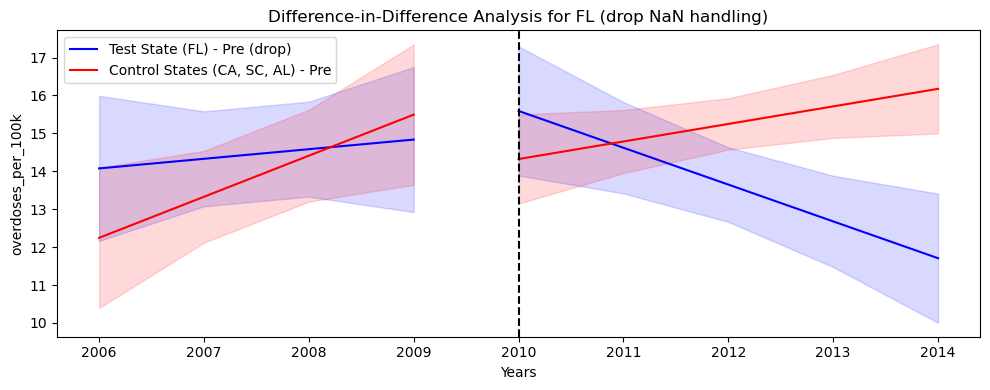

Simple DiD estimate for FL (drop): -2.185 in units of overdoses_per_100k.


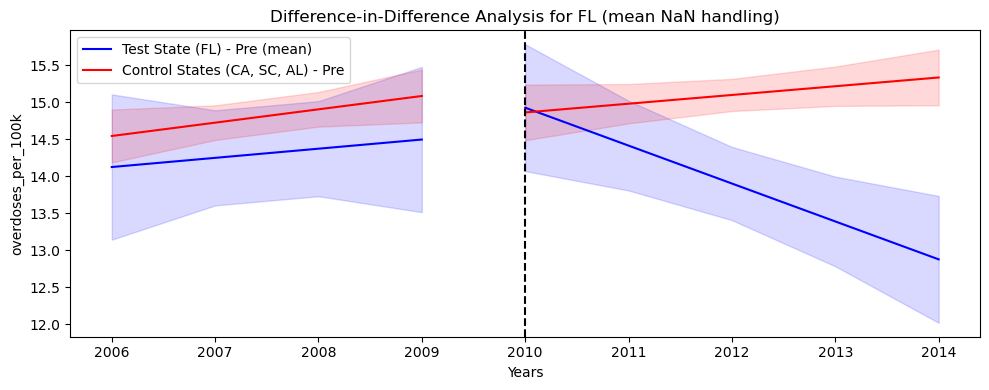

Simple DiD estimate for FL (mean): -0.693 in units of overdoses_per_100k.


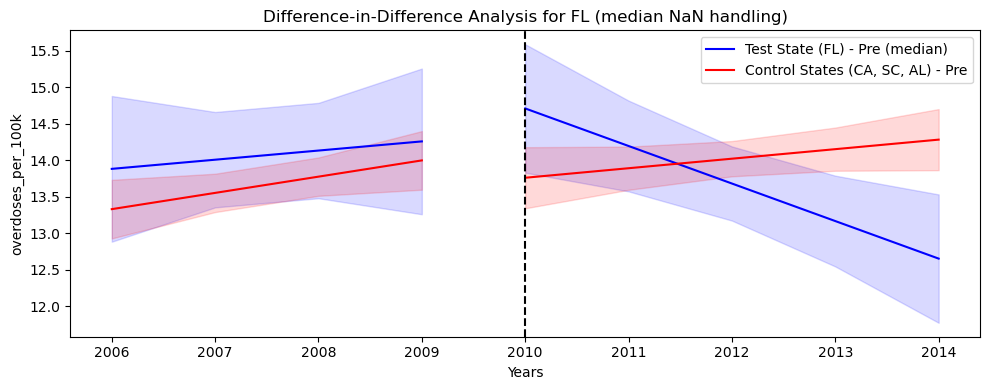

Simple DiD estimate for FL (median): -0.746 in units of overdoses_per_100k.


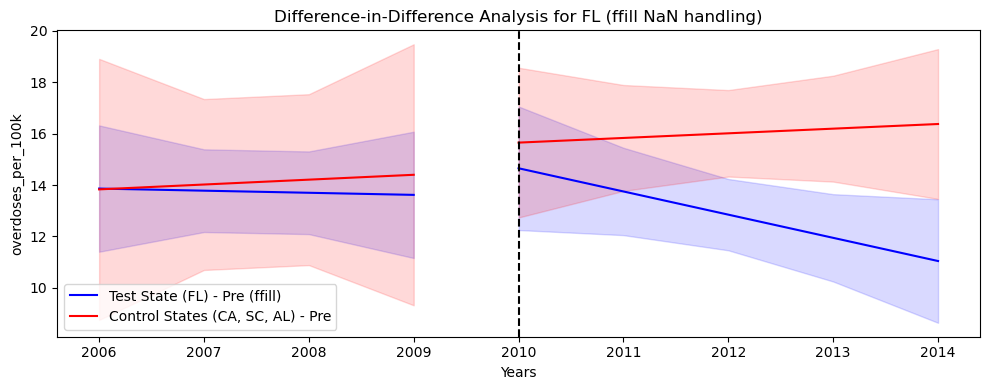

Simple DiD estimate for FL (ffill): -2.788 in units of overdoses_per_100k.


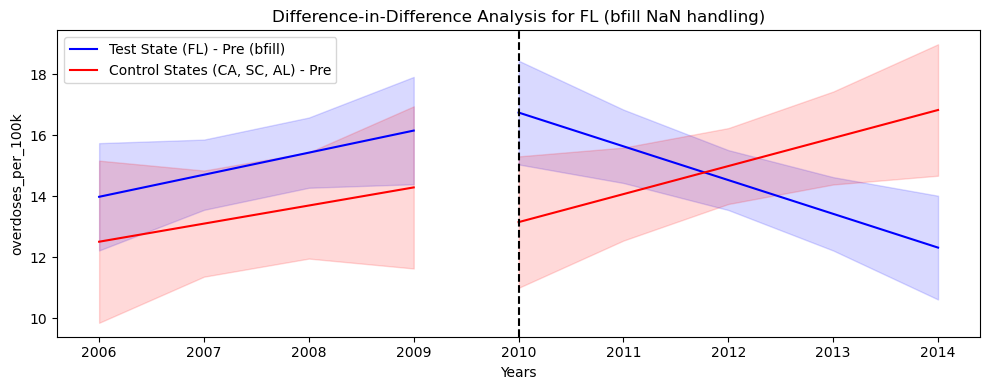

Simple DiD estimate for FL (bfill): -2.129 in units of overdoses_per_100k.


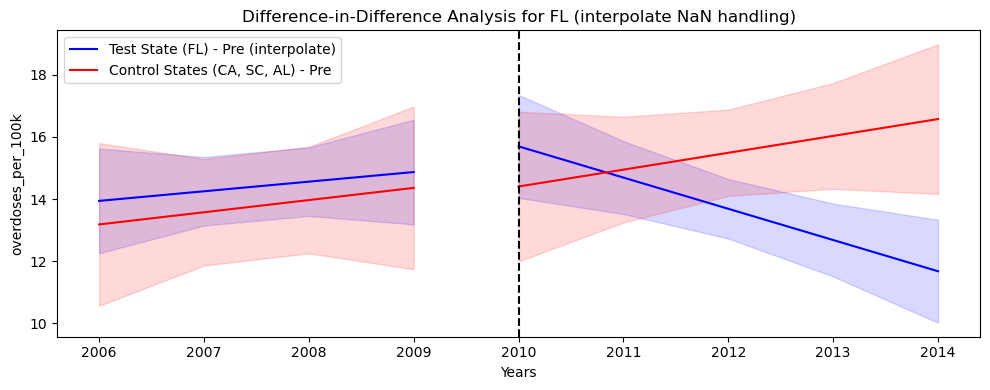

Simple DiD estimate for FL (interpolate): -2.436 in units of overdoses_per_100k.


In [23]:
# Florida
# 1. drop
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="drop",
)

# 2. mean
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="mean",
)

# 3. median
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="median",
)

# 4. ffill
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="interpolate",
)

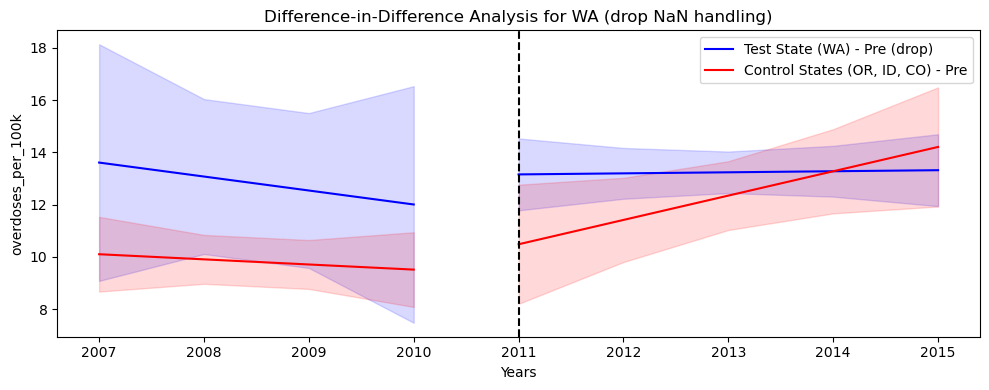

Simple DiD estimate for WA (drop): -2.106 in units of overdoses_per_100k.


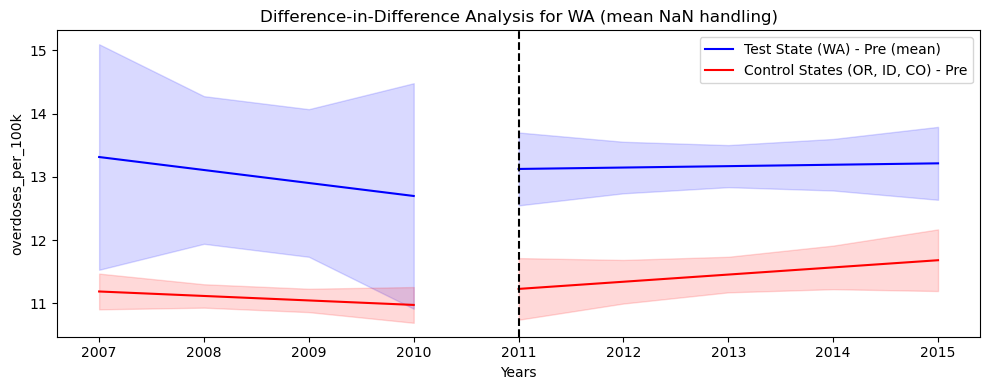

Simple DiD estimate for WA (mean): -0.210 in units of overdoses_per_100k.


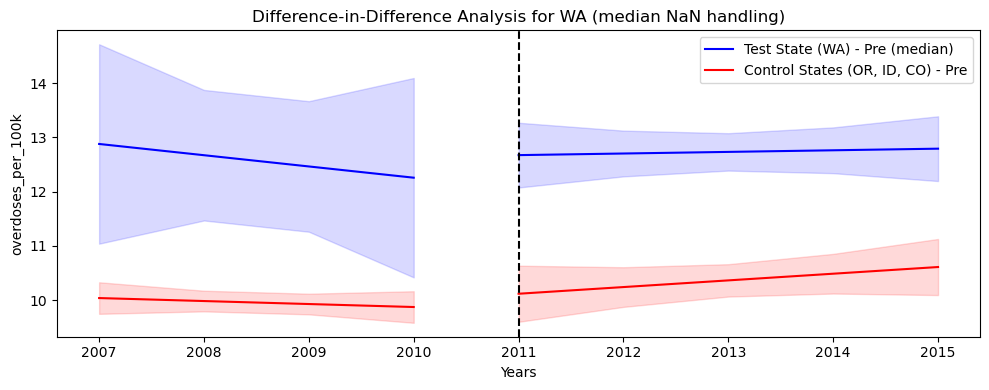

Simple DiD estimate for WA (median): -0.243 in units of overdoses_per_100k.


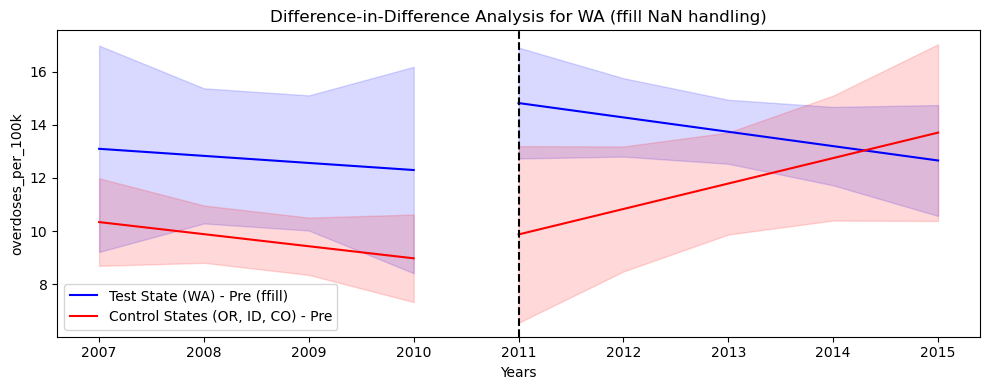

Simple DiD estimate for WA (ffill): -1.093 in units of overdoses_per_100k.


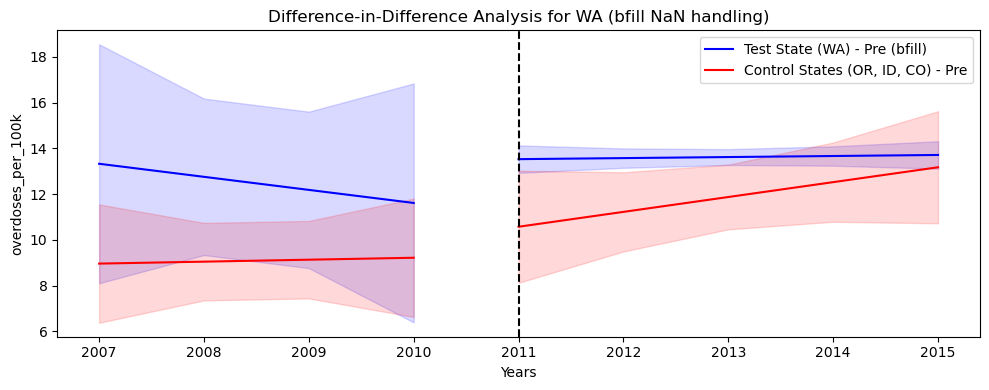

Simple DiD estimate for WA (bfill): -1.633 in units of overdoses_per_100k.


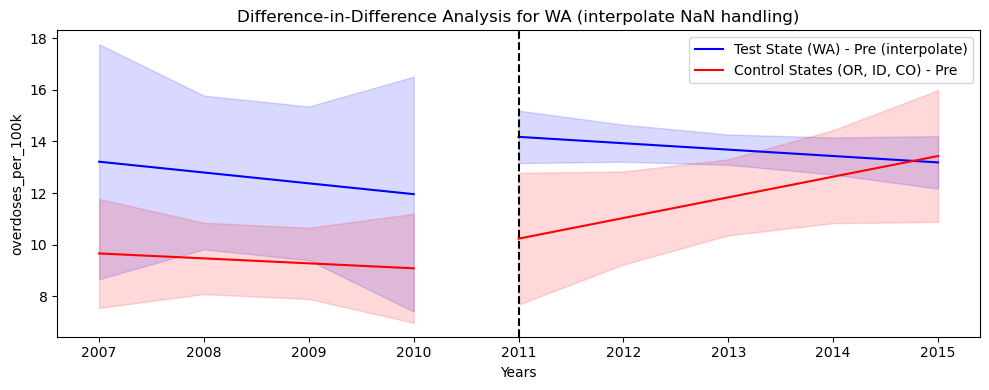

Simple DiD estimate for WA (interpolate): -1.364 in units of overdoses_per_100k.


In [24]:
# Washington
# 1. drop
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="drop",
)

# 2. mean
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="mean",
)

# 3. median
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="median",
)

# 4. ffill
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="interpolate",
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [25]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_did_grid(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
):
    """
    Draw 6 DiD plots (one for each NaN strategy) in a 3x2 grid.

    NaN strategies:
      - "drop"
      - "mean"
      - "median"
      - "ffill"
      - "bfill"
      - "interpolate"
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Use treated + control states only, for y-axis scaling
    use_states = [treated_state] + control_states
    subset = df[df["state"].isin(use_states)].copy()
    all_values = subset[rate_col].dropna()
    y_min, y_max = all_values.min(), all_values.max()

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        panel = subset.copy()

        # ---------- NaN handling ----------
        if strat != "drop":
            panel = panel.sort_values(["state", "year"])
            g = panel.groupby("state")

            if strat == "mean":
                panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
            elif strat == "median":
                panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.median()))
            elif strat == "ffill":
                panel[rate_col] = g[rate_col].transform(lambda s: s.ffill())
            elif strat == "bfill":
                panel[rate_col] = g[rate_col].transform(lambda s: s.bfill())
            elif strat == "interpolate":
                panel[rate_col] = g[rate_col].transform(
                    lambda s: s.interpolate(method="linear")
                )

        # ---------- aggregate to state-year ----------
        state_year = (
            panel.groupby(["state", "year"], as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # treated indicator
        state_year["treated"] = (state_year["state"] == treated_state).astype(int)

        # group averages (treated vs control)
        group_year = state_year.groupby(["treated", "year"], as_index=False)[
            "rate"
        ].mean()

        # pre / post masks
        pre_mask = (group_year["year"] >= policy_year - pre_window) & (
            group_year["year"] < policy_year
        )
        post_mask = (group_year["year"] >= policy_year) & (
            group_year["year"] <= policy_year + post_window
        )

        pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
        pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
        post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
        post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

        if (
            pre_treated.empty
            or pre_control.empty
            or post_treated.empty
            or post_control.empty
        ):
            ax.set_title(f"{strat} (not enough data)")
            ax.axis("off")
            continue

        # helper: OLS + CI
        def fit_segment(seg_df):
            X = sm.add_constant(seg_df["year"])
            model = sm.OLS(seg_df["rate"], X).fit()
            preds = model.get_prediction(X)
            mean = preds.predicted_mean
            ci = preds.conf_int(alpha=0.05)
            lower = ci[:, 0]
            upper = ci[:, 1]
            return mean, lower, upper

        tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
        tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
        co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
        co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

        # ---------- plot in this axis ----------
        x_pre_tr = pre_treated["year"].to_numpy()
        x_post_tr = post_treated["year"].to_numpy()
        x_pre_co = pre_control["year"].to_numpy()
        x_post_co = post_control["year"].to_numpy()

        # treated: blue
        ax.plot(x_pre_tr, tr_pre_mean, color="blue", label="Treated - Pre")
        ax.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

        ax.plot(
            x_post_tr, tr_post_mean, color="blue", linestyle="-", label="Treated - Post"
        )
        ax.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

        # control: red
        ax.plot(x_pre_co, co_pre_mean, color="red", label="Control - Pre")
        ax.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

        ax.plot(
            x_post_co, co_post_mean, color="red", linestyle="-", label="Control - Post"
        )
        ax.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

        # policy line
        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(f"{strat}", fontsize=11)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

        # optional: smaller legend inside each subplot
        ax.legend(fontsize=8, loc="best")

        # simple DiD estimate (for text / debugging)
        pre_tr_level = pre_treated["rate"].mean()
        post_tr_level = post_treated["rate"].mean()
        pre_co_level = pre_control["rate"].mean()
        post_co_level = post_control["rate"].mean()
        did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)
        print(
            f"{treated_state} - {strat}: DiD estimate = {did_estimate:.3f} in units of {rate_col}"
        )

    fig.suptitle(f"DiD for {treated_state} (6 NaN strategies)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

FL - drop: DiD estimate = -2.185 in units of overdoses_per_100k
FL - mean: DiD estimate = -0.693 in units of overdoses_per_100k
FL - median: DiD estimate = -0.746 in units of overdoses_per_100k
FL - ffill: DiD estimate = -2.788 in units of overdoses_per_100k
FL - bfill: DiD estimate = -2.129 in units of overdoses_per_100k
FL - interpolate: DiD estimate = -2.436 in units of overdoses_per_100k


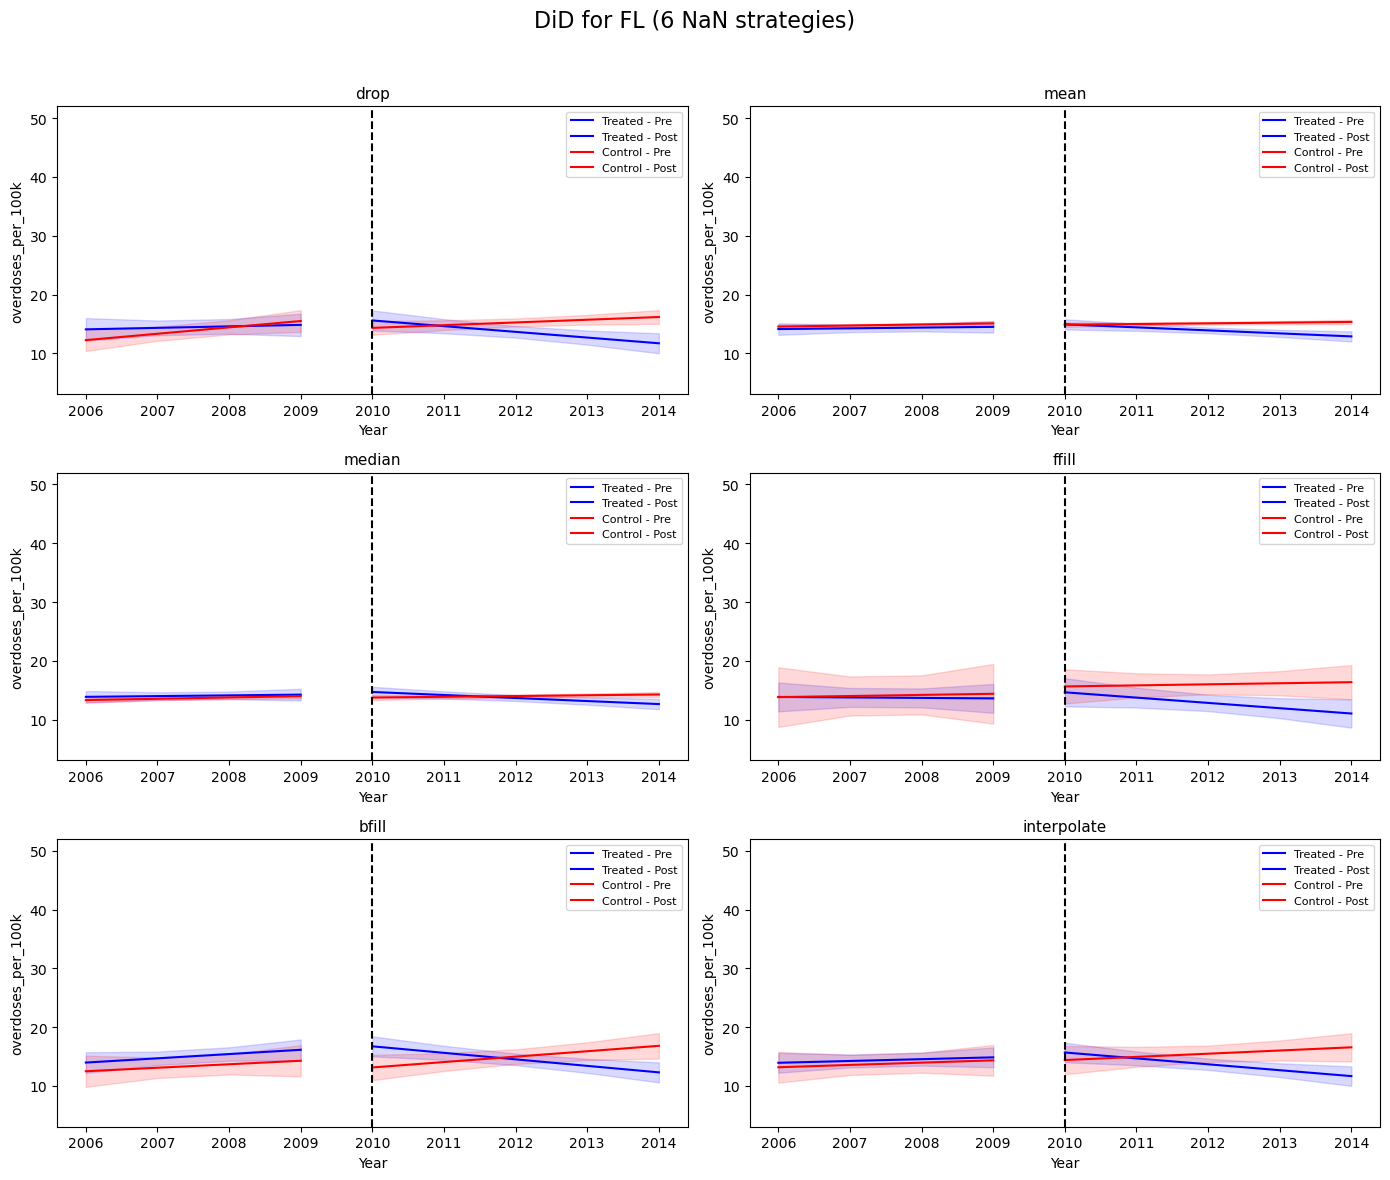

In [26]:
# Florida
plot_did_grid(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
)

WA - drop: DiD estimate = -2.106 in units of overdoses_per_100k
WA - mean: DiD estimate = -0.210 in units of overdoses_per_100k
WA - median: DiD estimate = -0.243 in units of overdoses_per_100k
WA - ffill: DiD estimate = -1.093 in units of overdoses_per_100k
WA - bfill: DiD estimate = -1.633 in units of overdoses_per_100k
WA - interpolate: DiD estimate = -1.364 in units of overdoses_per_100k


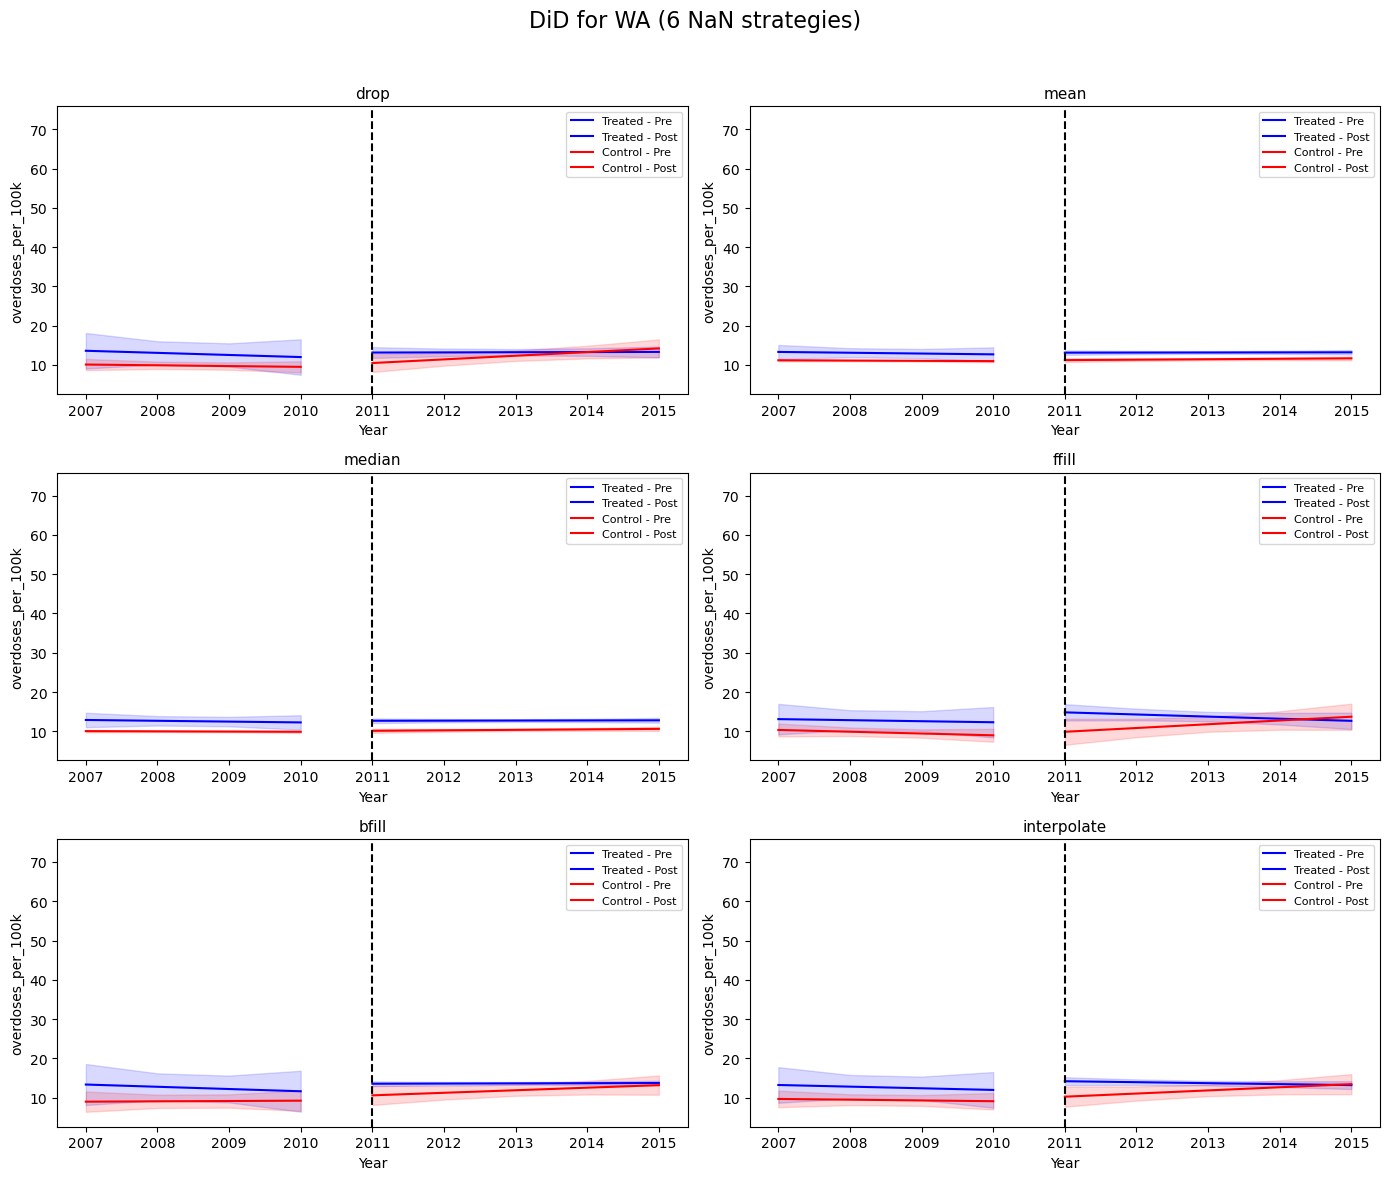

In [27]:
# Washington
plot_did_grid(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
)

## 4. Final Result (for Mortality) (Pending now)

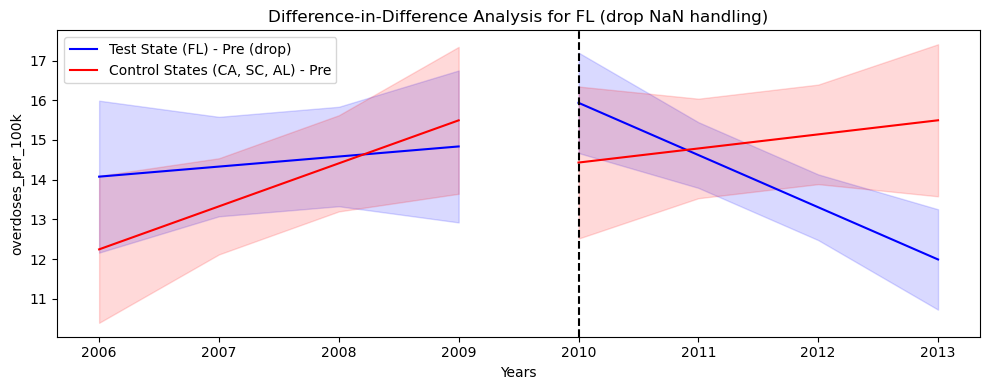

Simple DiD estimate for FL (drop): -1.587 in units of overdoses_per_100k.


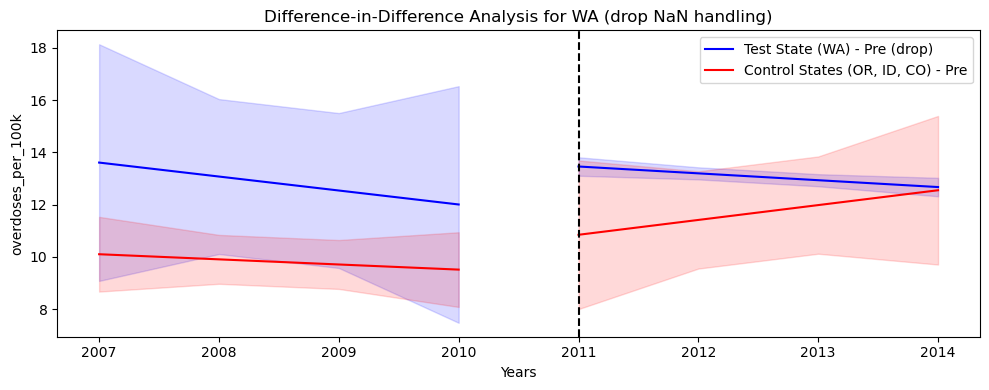

Simple DiD estimate for WA (drop): -1.631 in units of overdoses_per_100k.


In [28]:
# Florida: treated, controls = CA, SC, AL, policy year = 2010
plot_did_for_state(
    df=df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,  # years 2006–2009
    post_window=3,  # years 2010–2013; change to 4 if you want 2014 too
    nan_strategy="drop",
)

# Washington: treated, controls = OR, ID, CO, policy year = 2011
plot_did_for_state(
    df=df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,  # years 2007–2010
    post_window=3,  # years 2011–2014 (or 4 if you want 2015)
    nan_strategy="drop",
)

###############################################################################################################

# Shipment part

## 1. Define plot functions (replace NaN value + plot)

In [29]:
import statsmodels.api as sm
import matplotlib.pyplot as plt


def plot_did_shipment_for_state(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
    nan_strategy="drop",
):
    """
    Difference-in-Differences style plot for shipment outcome (e.g. mme_per_capita),
    with configurable NaN handling.

    NaN strategies:
      - "drop": leave NaN as is (they will be dropped later)
      - "mean": fill NaN with the state-specific mean
      - "median": fill NaN with the state-specific median
      - "ffill": forward fill within each state (sorted by year)
      - "bfill": backward fill within each state (sorted by year)
      - "interpolate": linear interpolation within each state (sorted by year)
    """

    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Keep only treated + control states
    use_states = [treated_state] + control_states
    panel = df[df["state"].isin(use_states)].copy()

    # ---------- NaN handling ----------
    if nan_strategy != "drop":
        panel = panel.sort_values(["state", "year"])
        g = panel.groupby("state")

        if nan_strategy == "mean":
            panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
        elif nan_strategy == "median":
            panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.median()))
        elif nan_strategy == "ffill":
            panel[rate_col] = g[rate_col].transform(lambda s: s.ffill())
        elif nan_strategy == "bfill":
            panel[rate_col] = g[rate_col].transform(lambda s: s.bfill())
        elif nan_strategy == "interpolate":
            panel[rate_col] = g[rate_col].transform(
                lambda s: s.interpolate(method="linear")
            )
        else:
            raise ValueError("Invalid nan_strategy choice.")

    # ---------- Aggregate to state-year ----------
    state_year = (
        panel.groupby(["state", "year"], as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
        .dropna(subset=["rate"])
    )

    # treated dummy
    state_year["treated"] = (state_year["state"] == treated_state).astype(int)

    # group averages by treated x year
    group_year = state_year.groupby(["treated", "year"], as_index=False)["rate"].mean()

    # pre / post masks
    pre_mask = (group_year["year"] >= policy_year - pre_window) & (
        group_year["year"] < policy_year
    )
    post_mask = (group_year["year"] >= policy_year) & (
        group_year["year"] <= policy_year + post_window
    )

    pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
    pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
    post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
    post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

    if (
        pre_treated.empty
        or pre_control.empty
        or post_treated.empty
        or post_control.empty
    ):
        print(f"Not enough data for given windows / states ({nan_strategy}).")
        return

    # ---------- helper: OLS + CI ----------
    def fit_segment(seg_df):
        X = sm.add_constant(seg_df["year"])
        model = sm.OLS(seg_df["rate"], X).fit()
        preds = model.get_prediction(X)
        mean = preds.predicted_mean
        ci = preds.conf_int(alpha=0.05)
        lower = ci[:, 0]
        upper = ci[:, 1]
        return mean, lower, upper

    tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
    tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
    co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
    co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

    # ---------- plot ----------
    plt.figure(figsize=(10, 4))

    x_pre_tr = pre_treated["year"].to_numpy()
    x_post_tr = post_treated["year"].to_numpy()
    x_pre_co = pre_control["year"].to_numpy()
    x_post_co = post_control["year"].to_numpy()

    # treated: blue
    plt.plot(x_pre_tr, tr_pre_mean, color="blue", label="Treated - Pre")
    plt.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

    plt.plot(x_post_tr, tr_post_mean, color="blue", label="Treated - Post")
    plt.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

    # control: red
    ctrl_label = "Control States (" + ", ".join(control_states) + ")"
    plt.plot(x_pre_co, co_pre_mean, color="red", label=ctrl_label + " - Pre")
    plt.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

    plt.plot(x_post_co, co_post_mean, color="red", label=ctrl_label + " - Post")
    plt.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

    # policy line
    plt.axvline(policy_year, color="black", linestyle="--")

    plt.title(
        f"DiD Shipment Analysis ({rate_col}) for {treated_state} [{nan_strategy}]"
    )
    plt.xlabel("Year")
    plt.ylabel(rate_col)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    # ---------- simple numeric DiD ----------
    pre_tr_level = pre_treated["rate"].mean()
    post_tr_level = post_treated["rate"].mean()
    pre_co_level = pre_control["rate"].mean()
    post_co_level = post_control["rate"].mean()

    did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)
    print(
        f"Shipment DiD estimate for {treated_state} ({nan_strategy}): "
        f"{did_estimate:.3f} in units of {rate_col}."
    )

## 2. Compare different NaN value dealing ways (bigger plots)

In [30]:
# Florida
# treated = FL, controls = CA, SC, AL, policy year = 2010

# 1. drop
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

Not enough data for given windows / states (drop).
Not enough data for given windows / states (mean).
Not enough data for given windows / states (median).
Not enough data for given windows / states (ffill).
Not enough data for given windows / states (bfill).
Not enough data for given windows / states (interpolate).


In [34]:
# Washington
# Washington shipment DiD, controls = OR, ID, CO, policy year = 2011

# 1. drop
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["CA", "SC", "AL"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

Not enough data for given windows / states (drop).
Not enough data for given windows / states (mean).
Not enough data for given windows / states (median).
Not enough data for given windows / states (ffill).
Not enough data for given windows / states (bfill).
Not enough data for given windows / states (interpolate).


## 3. Compare different NaN value dealing ways (smaller plots)

In [35]:
def plot_did_shipment_grid(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
):
    """
    Draw 6 DiD shipment plots (one for each NaN strategy) in a 3x2 grid.
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()
    use_states = [treated_state] + control_states
    subset = df[df["state"].isin(use_states)].copy()

    # for y-axis scaling
    all_vals = subset[rate_col].dropna()
    y_min, y_max = all_vals.min(), all_vals.max()

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        panel = subset.copy()

        # ----- NaN handling -----
        if strat != "drop":
            panel = panel.sort_values(["state", "year"])
            g = panel.groupby("state")

            if strat == "mean":
                panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
            elif strat == "median":
                panel[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.median()))
            elif strat == "ffill":
                panel[rate_col] = g[rate_col].transform(lambda s: s.ffill())
            elif strat == "bfill":
                panel[rate_col] = g[rate_col].transform(lambda s: s.bfill())
            elif strat == "interpolate":
                panel[rate_col] = g[rate_col].transform(
                    lambda s: s.interpolate(method="linear")
                )

        # aggregate to state-year
        state_year = (
            panel.groupby(["state", "year"], as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        state_year["treated"] = (state_year["state"] == treated_state).astype(int)
        group_year = state_year.groupby(["treated", "year"], as_index=False)[
            "rate"
        ].mean()

        pre_mask = (group_year["year"] >= policy_year - pre_window) & (
            group_year["year"] < policy_year
        )
        post_mask = (group_year["year"] >= policy_year) & (
            group_year["year"] <= policy_year + post_window
        )

        pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
        pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
        post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
        post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

        if (
            pre_treated.empty
            or pre_control.empty
            or post_treated.empty
            or post_control.empty
        ):
            ax.set_title(f"{strat} (not enough data)")
            ax.axis("off")
            continue

        def fit_segment(seg_df):
            X = sm.add_constant(seg_df["year"])
            model = sm.OLS(seg_df["rate"], X).fit()
            preds = model.get_prediction(X)
            mean = preds.predicted_mean
            ci = preds.conf_int(alpha=0.05)
            lower = ci[:, 0]
            upper = ci[:, 1]
            return mean, lower, upper

        tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
        tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
        co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
        co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

        x_pre_tr = pre_treated["year"].to_numpy()
        x_post_tr = post_treated["year"].to_numpy()
        x_pre_co = pre_control["year"].to_numpy()
        x_post_co = post_control["year"].to_numpy()

        # treated: blue
        ax.plot(x_pre_tr, tr_pre_mean, color="blue")
        ax.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)
        ax.plot(x_post_tr, tr_post_mean, color="blue")
        ax.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

        # control: red
        ax.plot(x_pre_co, co_pre_mean, color="red")
        ax.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)
        ax.plot(x_post_co, co_post_mean, color="red")
        ax.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")
        ax.set_title(strat, fontsize=11)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

    fig.suptitle(
        f"Shipment DiD for {treated_state} ({rate_col}) — 6 NaN strategies",
        fontsize=16,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

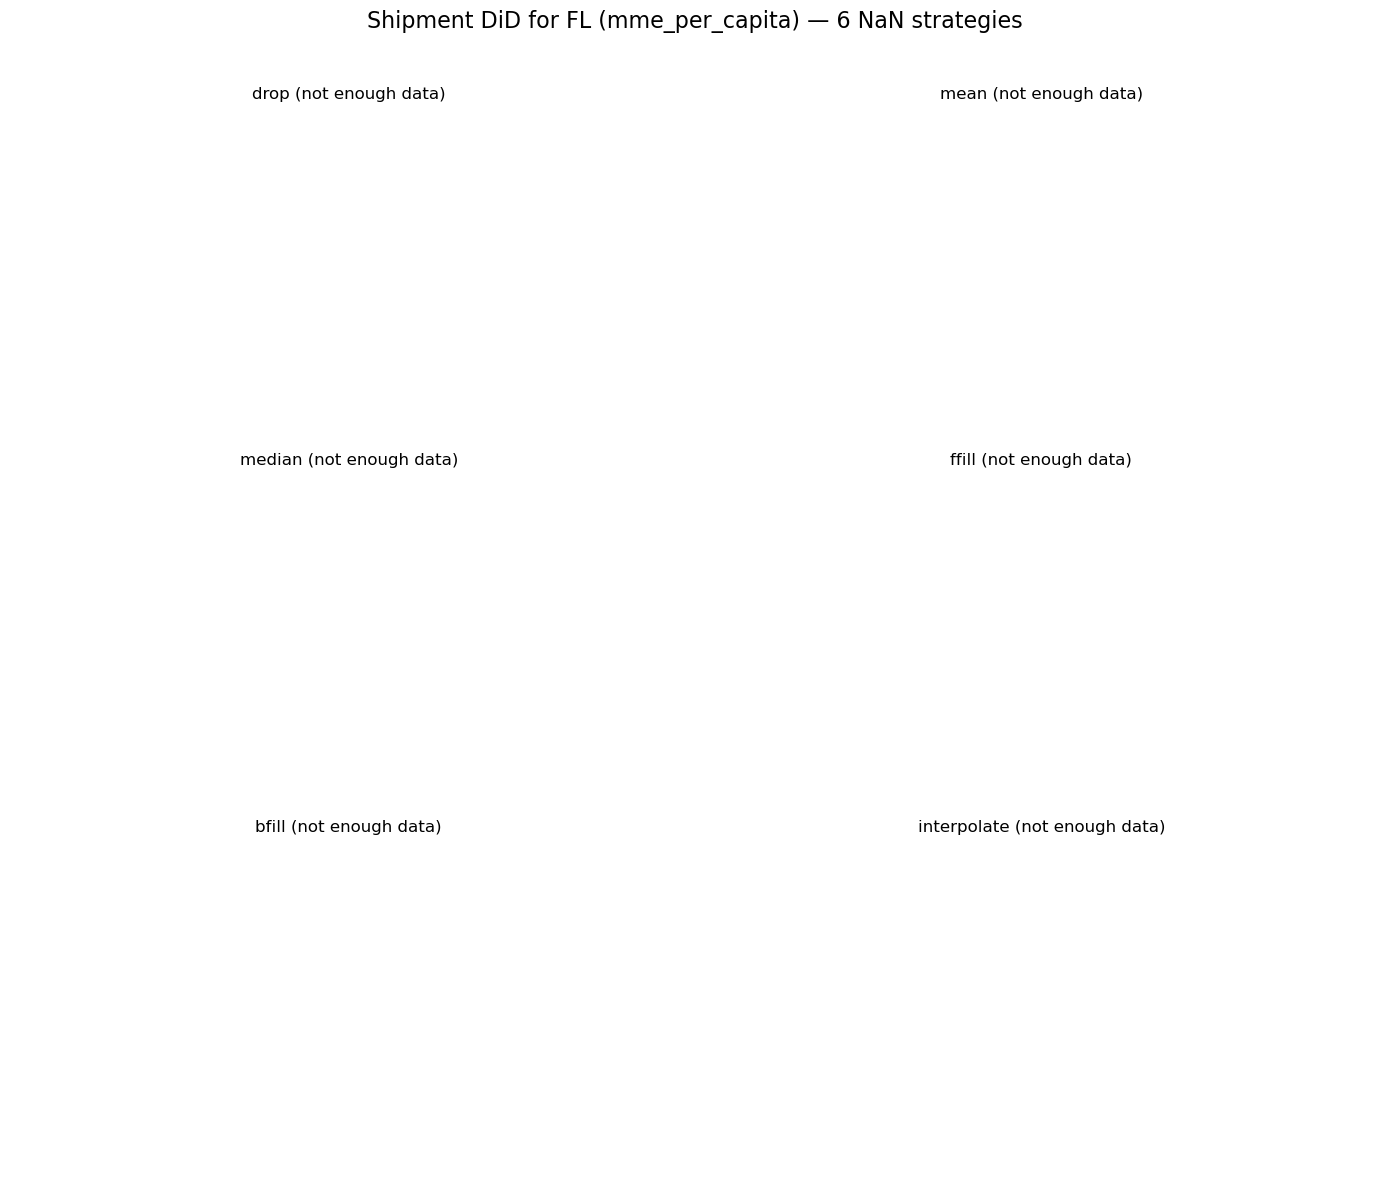

In [36]:
# Florida
plot_did_shipment_grid(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
)

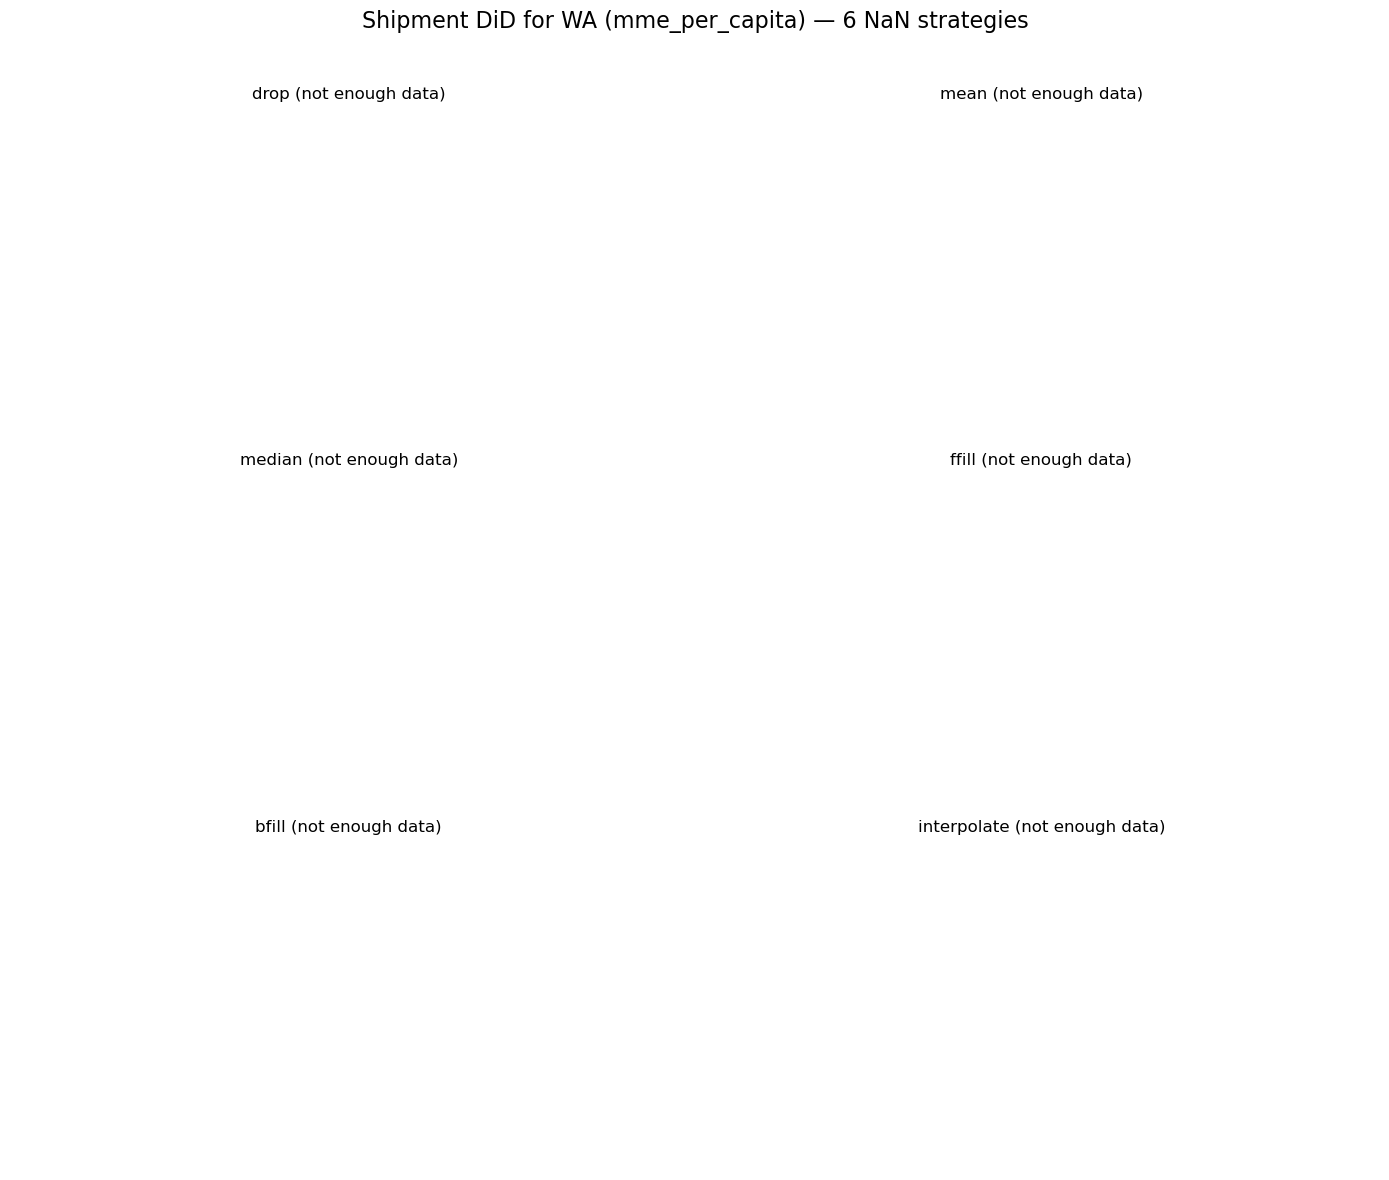

In [37]:
# Washington
plot_did_shipment_grid(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
)

## 4. Final Result (for Mortality) (Pending now)